In [26]:
#step1:
# import the pandas for data handling and manipulation
import pandas as pd
# ttest_ind for performing an independent two-sample t-test
from scipy.stats import  ttest_ind
df = pd.read_csv("Life Expectancy Data.csv")


In [27]:
#step2:
# Select only needed columns and remove rows with missing values
df_cleaned = df[['Status', 'Life expectancy ']].dropna()
# View sample
df_cleaned.head()

,Status,Life expectancy
0,Developing,65.0
1,Developing,59.9
2,Developing,59.9
3,Developing,59.5
4,Developing,59.2


In [28]:
#step3:
# Developed and Developing life expectancy samples from the dataset
import numpy as np

Developed = np.array(developed)
Developing = np.array(developing)

l1 = len(Developed)  # Number of developed country records
l2 = len(Developing)  # Number of developing country records

# Display the lengths
print("Sample size of Developed countries (l1):", l1)
print("Sample size of Developing countries (l2):", l2)

Sample size of Developed countries (l1): 512
Sample size of Developing countries (l2): 2416


In [29]:
# Step4: Calculate statistics

# Calculate the mean (average life expectancy) for developed countries (x₁)
x1_mean = developed.mean()

# Calculate the mean (average life expectancy) for developing countries (x₂)
x2_mean = developing.mean()

# Count the number of observations in each group 
n1 = len(developed)   # Number of developed country records (n1)
n2 = len(developing)  # Number of developing country records (n2)

# Calculate the sample variance (s₁^2) for developed countries
# ddof=1 means sample variance 
s1_squared = developed.var(ddof=1)

# Calculate the sample variance (s₂^2) for developing countries
s2_squared = developing.var(ddof=1)

In [30]:
#step5:
# Group data by 'Status'
developed = df_cleaned[df_cleaned['Status'] == 'Developed']['Life expectancy ']
developing = df_cleaned[df_cleaned['Status'] == 'Developing']['Life expectancy ']

In [31]:
# Step 6: Calculate the Pooled Standard Error (SE)
# We're comparing the means of two independent groups (Developed vs Developing).
# Since the variances of the two groups may differ, we use a pooled estimate of the standard error

# The rule we apply is:
#  SE = √[ ((n₁ - 1)s₁² + (n₂ - 1)s₂²) / (n₁ + n₂ - 2) × (1/n₁ + 1/n₂) ]

# Calculate pooled variance 
pooled_variance = ((n1 - 1) * s1_squared + (n2 - 1) * s2_squared) / (n1 + n2 - 2)

# Now calculate the full standard error using the rule
SE = math.sqrt(pooled_variance * (1/n1 + 1/n2))


In [32]:
# Step7: Manual t-test statistic
t_stat = (x1_mean - x2_mean) / SE

In [33]:
# Step 8: Print all values
print("Mean (Developed):", round(x1_mean, 2))
print("Mean (Developing):", round(x2_mean, 2))
print("Sample size (n1):", n1)
print("Sample size (n2):", n2)
print("Variance (Developed):", round(s1_squared, 2))
print("Variance (Developing):", round(s2_squared, 2))
print("Pooled Standard Error:", round(SE, 4))
print("t-statistic:", round(t_stat, 4))

Mean (Developed): 79.2
Mean (Developing): 67.11
Sample size (n1): 512
Sample size (n2): 2416
Variance (Developed): 15.45
Variance (Developing): 81.11
Pooled Standard Error: 0.406
t-statistic: 29.7684


In [13]:
#step9:Degree of freedom for developed vs developing t-test
degree_freedom = n1 + n2 - 2
print("Degrees of Freedom:", degree_freedom)

Degrees of Freedom: 2926


In [34]:
# Step 10: Find the critical t-value for a two-tailed test at 95% confidence level (α = 0.05)
# We're using the t-distribution because we're comparing two sample means with estimated variance.
# Since it's a two-tailed test, we divide alpha by 2 to check both sides of the distribution.
from scipy.stats import t
alpha = 0.05
t_critical = t.ppf(1 - alpha / 2, degree_freedom)  # degree_freedom = n1 + n2 - 2 

#Step 11: Display the critical value
# This value tells us the minimum t-score needed to say the difference is statistically significant.

print("Critical t-value (α = 0.05, two-tailed):", round(t_critical, 4))

Critical t-value (α = 0.05, two-tailed): 1.9608


In [35]:
# Final Step: Make a decision based on the comparison of t-statistic and critical value

# If the absolute t value is less than the critical value, the difference is not strong enough
if abs(t_stat) < t_critical:
    print(f" The absolute t-value ({round(t_stat, 4)}) is smaller than the critical value ({round(t_critical, 4)}).")
    print("We do not have enough evidence to reject the null hypothesis (H0).")
    print("Conclusion: There is no significant difference in life expectancy between Developed and Developing countries.")
else:
    print(f"The absolute t-value ({round(t_stat, 4)}) is greater than or equal to the critical value ({round(t_critical, 4)}).")
    print("We reject the null hypothesis (H0).")
    print("Conclusion: There is a statistically significant difference in life expectancy between Developed and Developing countries.")



The absolute t-value (29.7684) is greater than or equal to the critical value (1.9608).
We reject the null hypothesis (H0).
Conclusion: There is a statistically significant difference in life expectancy between Developed and Developing countries.


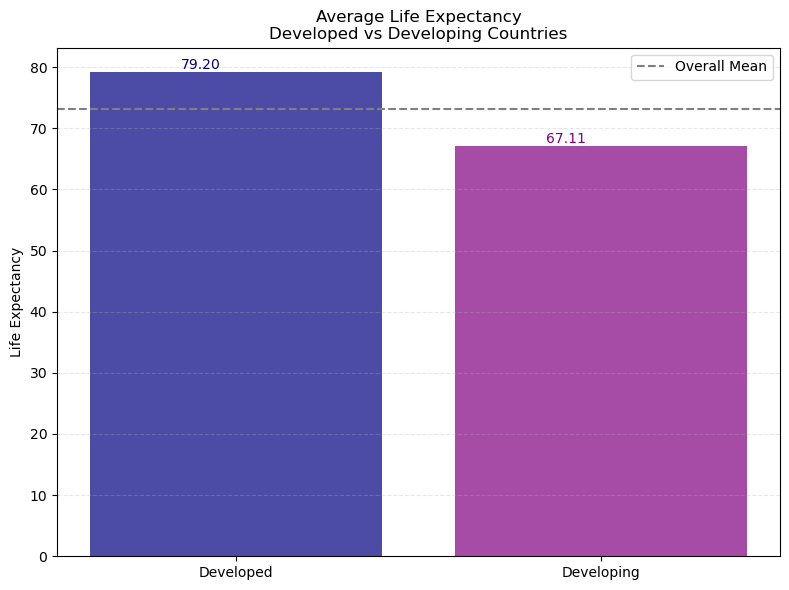

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Create a bar chart comparing the average life expectancy
plt.figure(figsize=(8, 6))

# Bar chart for group means
plt.bar(['Developed', 'Developing'], [x1_mean, x2_mean], color=['navy', 'purple'], alpha=0.7)

# Add a dashed line for the overall mean
overall_mean = np.mean([x1_mean, x2_mean])
plt.axhline(y=overall_mean, color='gray', linestyle='--', label='Overall Mean')

# Add text labels for each bar
plt.text(-0.15, x1_mean + 0.5, f"{x1_mean:.2f}", color='navy', fontsize=10)
plt.text(0.85, x2_mean + 0.5, f"{x2_mean:.2f}", color='purple', fontsize=10)

# Customize the plot
plt.title('Average Life Expectancy\nDeveloped vs Developing Countries')
plt.ylabel('Life Expectancy')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.legend()
plt.tight_layout()

# Show the plot
plt.show()


In [39]:
# Summary of the Hypothesis Test

summary = [
    ["Step 1", "We wrote our hypotheses (H0 and H1)", "To check if there's a real difference"],
    ["Step 2", "We picked alpha = 0.05", "That's our limit for deciding if a result is unusual"],
    ["Step 3", "We found the means, sizes, and variances of both groups", "Needed for the t-test formula"],
    ["Step 4", "We calculated the pooled standard error", "To measure how spread out the data is"],
    ["Step 5", "We calculated the t-statistic", "To see how far apart the means are"],
    ["Step 6", "We found the critical t-value (±1.96)", "This is our decision cutoff"],
    ["Step 7", "We compared t-stat with the cutoff", "Our t was much bigger than 1.96"],
    ["Step 8", "We rejected the null hypothesis", " There's a real difference in life expectancy!"]
]

# Print each step nicely
print("\n Hypothesis Test Summary:")
for step in summary:
    print(f"{step[0]}: {step[1]} — {step[2]}")



 Hypothesis Test Summary:
Step 1: We wrote our hypotheses (H0 and H1) — To check if there's a real difference
Step 2: We picked alpha = 0.05 — That's our limit for deciding if a result is unusual
Step 3: We found the means, sizes, and variances of both groups — Needed for the t-test formula
Step 4: We calculated the pooled standard error — To measure how spread out the data is
Step 5: We calculated the t-statistic — To see how far apart the means are
Step 6: We found the critical t-value (±1.96) — This is our decision cutoff
Step 7: We compared t-stat with the cutoff — Our t was much bigger than 1.96
Step 8: We rejected the null hypothesis —  There's a real difference in life expectancy!
